In [35]:
import numpy as np
import matplotlib.pyplot as plt

In [36]:
from google.colab import drive
drive.mount('/content/drive')
imgpath = '/content/drive/MyDrive/DIP4E'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [37]:
f = plt.imread(imgpath+'/dentalXray-pepper-noise.tif')
print(f.shape, f.dtype, f.min(), f.max())

(680, 888) uint8 0 255


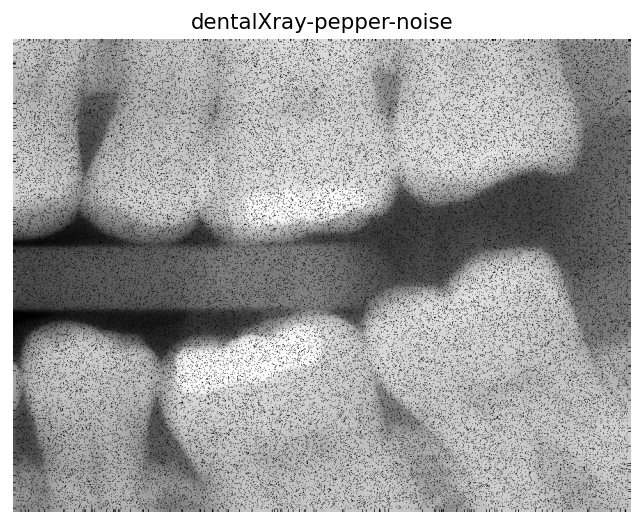

In [38]:
plt.figure(dpi=128)
plt.imshow(f, cmap='gray', aspect='equal', vmin=0, vmax=255)
plt.axis('off')
plt.title('dentalXray-pepper-noise')
plt.show()

# **1. Arithmetic Mean**

In [39]:
SS = 7 # kernel size (square kernel)
ss = int((SS-1)/2)

f = f.astype(np.float64)
r_mean = f.copy()

In [40]:
for x in range(ss, np.size(f,0)-ss):
  for y in range(ss, np.size(f,1)-ss):
    Sxy = f[x-ss:x-ss+SS, y-ss:y-ss+SS]
    r_mean[x,y] = np.mean(Sxy)

# **2. Median**

In [41]:
SS = 7 # kernel size (square kernel)
ss = int((SS-1)/2)

r_median = f.copy()

In [42]:
for x in range(ss, np.size(f,0)-ss):
  for y in range(ss, np.size(f,1)-ss):
    Sxy = f[x-ss:x-ss+SS, y-ss:y-ss+SS]
    r_median[x,y] = np.median(Sxy)

# **3. Adaptive local noise reduction**

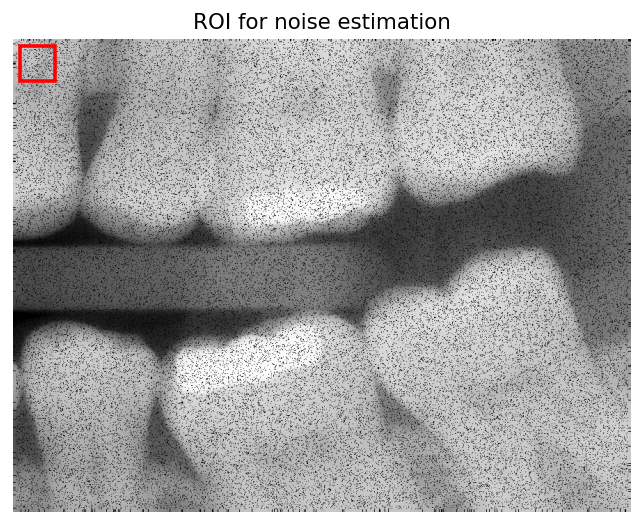

estimated noise std: 58.645518565701174


In [43]:
r0, r1, c0, c1 = 10, 60, 10, 60

plt.figure(dpi=128)
plt.imshow(f, cmap='gray', aspect='equal', vmin=0, vmax=255)
plt.gca().add_patch(plt.Rectangle((c0,r0), c1-c0, r1-r0, fill=False, edgecolor='r', lw=2))
plt.axis('off')
plt.title('ROI for noise estimation')
plt.show()

std_eta = np.std(f[r0:r1, c0:c1])
print('estimated noise std:', std_eta)

In [44]:
SS = 7
ss = int((SS-1)/2)

r_amean = f.copy()

In [45]:
for x in range(ss, np.size(f,0)-ss):
  for y in range(ss, np.size(f,1)-ss):
    Sxy = f[x-ss:x-ss+SS, y-ss:y-ss+SS]
    std_Sxy = np.std(Sxy)
    if std_Sxy == 0:
      r_amean[x,y] = f[x,y]
    else:
      ratio = min((std_eta*std_eta)/(std_Sxy*std_Sxy), 1.0)
      r_amean[x,y] = f[x,y] - ratio*(f[x,y]-np.mean(Sxy))

# **결과**

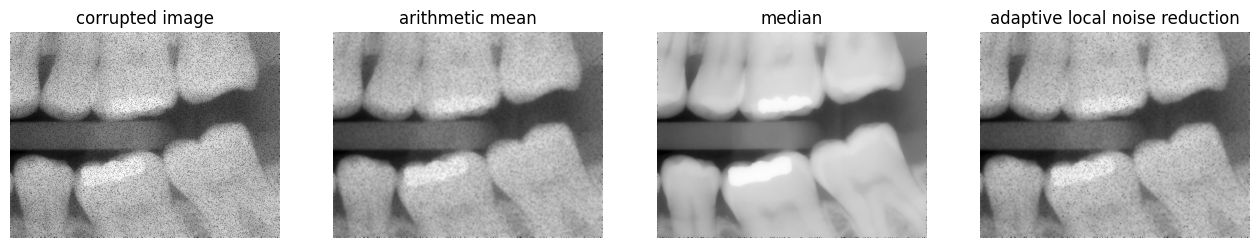

In [46]:
plt.figure(figsize=(16,9))
plt.subplot(141)
plt.imshow(f,cmap='gray',aspect='equal',vmin=0,vmax=255)
plt.axis('off')
plt.title('corrupted image')
plt.subplot(142)
plt.imshow(r_mean,cmap='gray',aspect='equal',vmin=0,vmax=255)
plt.axis('off')
plt.title('arithmetic mean')
plt.subplot(143)
plt.imshow(r_median,cmap='gray',aspect='equal',vmin=0,vmax=255)
plt.axis('off')
plt.title('median')
plt.subplot(144)
plt.imshow(r_amean,cmap='gray',aspect='equal',vmin=0,vmax=255)
plt.axis('off')
plt.title('adaptive local noise reduction')
plt.show()

In [47]:
plt.imsave('dentalXray-mean.png', r_mean, cmap='gray', vmin=0, vmax=255)
plt.imsave('dentalXray-median.png', r_median, cmap='gray', vmin=0, vmax=255)
plt.imsave('dentalXray-adaptive.png', r_amean, cmap='gray', vmin=0, vmax=255)

Median이 pepper 잡음 제거에 가장 효과적이었다.